In [92]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import LabelEncoder 
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Multiple linear regression model

## Task 1: Baseline Modeling
Load the WHO Life Expectancy Dataset, remove non-numeric columns (Country, Year), Convert Status column to  numeric, handle missing values.
- Use StandardScaler from sklearn.preprocessing to scale all independent variables. ("Life expectancy" is dependent variable) 
- Train a LinearRegression model using the scaled features.
- Report the R-Squared Score.
- Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.

## Task 2: Iterative Diagnostic (VIF < 5)
Before analyzing the data, you must understand the Variance Inflation Factor (VIF) diagnostic. VIF measures multicollinearity, the degree to which your predictors are redundant.
High multicollinearity inflates the variance of coefficients, making them unreliable and difficult to interpret.
VIF is calculated by regressing one predictor against all others, then you obtain R_Squared and then compute VIF = 1/(1-R_Squared)
You sohuld use a cutoff of 5. Any variable with a VIF > 5 is considered too redundant and will be removed to improve the model's structural integrity. To do that follow the instruction below:

### Write a loop to iteratively remove the most redundant feature:
    1. Calculate VIF for every feature in the scaled dataset.
    2. Find the variable with the highest VIF.
    3. If VIF > 5, remove that feature from the data.
    4. Repeats the process until all remaining features have a VIF < 5
    - Note that in each iteration you remove only the highest VIF if it is greatet than 5!
    
## Task 3: Comparison of Model Results
    - Train a new LinearRegression model using only the independent features that survived the VIF diagnostic test.
    - Report the R-Squared Score.
    - Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.
    - Are the top 5 predicotrs remain the same as those of the Baseline Model?

## Task 4: Residual Analysis and Normality
A good regression model should have errors (residuals) that are normally distributed and centered around zero.

    - Generate a histogram of the residuals for your baseline and clean model side by side.
    - Does the error distributions look like a bell curve?

## Task 5: The Interaction Investigation
In the real world application, the effect of one variable often depends on another. This is called an interaction.

    - Select two variables of your choice from the dataset (only variables with VIF < 5) that you believe might have a combined effect (e.g., Alcohol and GDP, or BMI and HIV/AIDS,). Write one sentence explaining why you think they interact.
    - Create a new column in your dataframe by multiplying these two variables together.
    - Train a new model by adding this new interaction term to your dataset and fit it again using LinearRegression.
    - Report the R-Squared Score.
    - Is the interaction coeficient positive or negative? Has adding it improved the Model performance?

## Task 1: Baseline Modeling

In [93]:
df = pd.read_csv('Life Expectancy Data.csv')
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [103]:
df = df.drop(columns=["Country", "Year"])
le = LabelEncoder()
df['Status'] = le.fit_transform(df['Status']) # turning the status column into a 0 and 1, numeric values

### Cleaning

In [105]:
#df.isna().sum()
df.columns = [
    "Status",
    "Life expectancy",
    "Adult Mortality",
    "infant deaths",
    "Alcohol",
    "percentage expenditure",
    "Hepatitis B",
    "Measles",
    "BMI",
    "under-five deaths",
    "Polio",
    "Total expenditure",
    "Diphtheria",
    "HIV/AIDS",
    "GDP",
    "Population",
    "thinness 1-19 years",
    "thinness 5-9 years",
    "Income composition of resources",
    "Schooling"]

df = df.dropna(subset=["Life expectancy"])
df["Adult Mortality"] = df["Adult Mortality"].fillna(df["Adult Mortality"].median())
df["Alcohol"] = df["Alcohol"].fillna(df["Alcohol"].median())
df["Hepatitis B"] = df["Hepatitis B"].fillna(df["Hepatitis B"].median())
df["BMI"] = df["BMI"].fillna(df["BMI"].median())
df["Polio"] = df["Polio"].fillna(df["Polio"].median())
df["Total expenditure"] = df["Total expenditure"].fillna(df["Total expenditure"].median())
df["Diphtheria"] = df["Diphtheria"].fillna(df["Diphtheria"].median())
df["GDP"] = df["GDP"].fillna(df["GDP"].median())
df["Population"] = df["Population"].fillna(df["Population"].median())
df["thinness 1-19 years"] = df["thinness 1-19 years"].fillna(df["thinness 1-19 years"].median())
df["thinness 5-9 years"] = df["thinness 5-9 years"].fillna(df["thinness 5-9 years"].median())
df["Income composition of resources"] = df["Income composition of resources"].fillna(df["Income composition of resources"].median())
df["Schooling"] = df["Schooling"].fillna(df["Schooling"].median())

### First model

In [159]:
X = df[["Status",
    "Adult Mortality",
    "infant deaths",
    "Alcohol",
    "percentage expenditure",
    "Hepatitis B",
    "Measles",
    "BMI",
    "under-five deaths",
    "Polio",
    "Total expenditure",
    "Diphtheria",
    "HIV/AIDS",
    "GDP",
    "Population",
    "thinness 1-19 years",
    "thinness 5-9 years",
    "Income composition of resources",
    "Schooling"]]
Y = df['Life expectancy']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_strain, X_stest, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=10)

In [155]:
model = LinearRegression()
model.fit(X_strain, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[-0.56,-2.57,12.28,..., 0.17, 1.1 , 2.08]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,69.24
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(19)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](19,)","[118.3 , 81.27, 64.01,..., 14.79, 12.5 , 2.6 ]"


In [156]:
Y_predicted = model.predict(X_stest)

print(f"R-squared Score: {r2_score(Y_test, Y_predicted):.2f}")

print("Coefficients:")
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_})



coef_df_order = coef_df.sort_values(by="Coefficient", key=abs, ascending=False)

print(coef_df_order)

print(f"Intercept is: {model.intercept_:.2f}")

R-squared Score: 0.81
Coefficients:
                            Feature  Coefficient
8                 under-five deaths   -12.604427
2                     infant deaths    12.282203
1                   Adult Mortality    -2.567869
12                         HIV/AIDS    -2.353507
18                        Schooling     2.082164
17  Income composition of resources     1.099925
11                       Diphtheria     1.015971
7                               BMI     0.927768
9                             Polio     0.628217
13                              GDP     0.596715
0                            Status    -0.564753
15              thinness 1-19 years    -0.418620
5                       Hepatitis B    -0.409024
3                           Alcohol     0.329451
6                           Measles    -0.235633
10                Total expenditure     0.216069
16               thinness 5-9 years     0.174566
14                       Population     0.029756
4            percentage expenditu

## Task 2: Iterative Diagnostic (VIF < 5)


In [160]:
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

while True:

    vif_df = pd.DataFrame()

    vif_df["Feature"] = X_scaled.columns

    vif_df["VIF"] = [variance_inflation_factor(X_scaled.values, i)
        for i in range(X_scaled.shape[1])]

    vif_df = vif_df.sort_values("VIF", ascending=False)

    print(vif_df)

    highest_vif = vif_df.iloc[0, 1]
    highest_feature = vif_df.iloc[0, 0]

    if highest_vif > 5:
        print(f"\nRemoving {highest_feature} ({highest_vif:.2f})")
        X_scaled = X_scaled.drop(columns=[highest_feature])

    else:
        print("\nAll features have a VIF of 5 or less.")
        break

# https://www.geeksforgeeks.org/python/how-to-use-while-true-in-python/
# https://www.geeksforgeeks.org/python/detecting-multicollinearity-with-vif-python/

                            Feature         VIF
2                     infant deaths  177.201540
8                 under-five deaths  176.155410
16               thinness 5-9 years    8.852724
15              thinness 1-19 years    8.749254
13                              GDP    5.987690
4            percentage expenditure    5.773059
18                        Schooling    3.396331
17  Income composition of resources    3.051476
11                       Diphtheria    2.149715
9                             Polio    1.931063
0                            Status    1.878606
3                           Alcohol    1.848382
1                   Adult Mortality    1.734045
7                               BMI    1.727522
14                       Population    1.490071
12                         HIV/AIDS    1.422533
6                           Measles    1.378783
5                       Hepatitis B    1.309039
10                Total expenditure    1.211535

Removing infant deaths (177.20)
       

## Task 3: Comparison of Model Results

### Second model

In [141]:
X2 = df[["Status",
    "Adult Mortality",
    "Alcohol",
    "percentage expenditure",
    "Hepatitis B",
    "Measles",
    "BMI",
    "under-five deaths",
    "Polio",
    "Total expenditure",
    "Diphtheria",
    "HIV/AIDS",
    "Population",
    "thinness 1-19 years",
    "Income composition of resources",
    "Schooling"]]
Y2 = df['Life expectancy']

scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

X2_train, X2_test, Y2_train, Y2_test = train_test_split(X2_scaled, Y2, test_size=0.2, random_state=10)

In [111]:
model2 = LinearRegression()
model2.fit(X2_train, Y2_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[-0.58,-2.64, 0.15,...,-0.19, 1.29, 2.14]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,69.24
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](16,)","[107.23, 69.88, 61.3 ,..., 27.36, 25.6 , 21.02]"


In [152]:
Y2_predicted = model2.predict(X2_test)

print(f"R-squared Score: {r2_score(Y2_test, Y2_predicted):.2f}")

print("Coefficients:")
coef_df2 = pd.DataFrame({
    "Feature": X2.columns,
    "Coefficient": model2.coef_})

coef_df2_order = coef_df2.sort_values(by="Coefficient", key=abs, ascending=False)

print(coef_df2_order)

print(f"Intercept is: {model2.intercept_:.2f}")

R-squared Score: 0.81
Coefficients:
                            Feature  Coefficient
1                   Adult Mortality    -2.636366
11                         HIV/AIDS    -2.407213
15                        Schooling     2.135669
14  Income composition of resources     1.285758
10                       Diphtheria     1.177406
6                               BMI     0.957244
8                             Polio     0.726666
0                            Status    -0.576142
3            percentage expenditure     0.499076
7                 under-five deaths    -0.474416
4                       Hepatitis B    -0.466621
12                       Population     0.247192
5                           Measles    -0.205513
9                 Total expenditure     0.197079
13              thinness 1-19 years    -0.188305
2                           Alcohol     0.147968
Intercept is: 69.24


**The top 5 predicotrs are the same as those of the Baseline Model: Adult Mortality, HIV/AIDS, Schooling, Income composition of resources, and Diphtheria.**

## Task 4: Residual Analysis and Normality

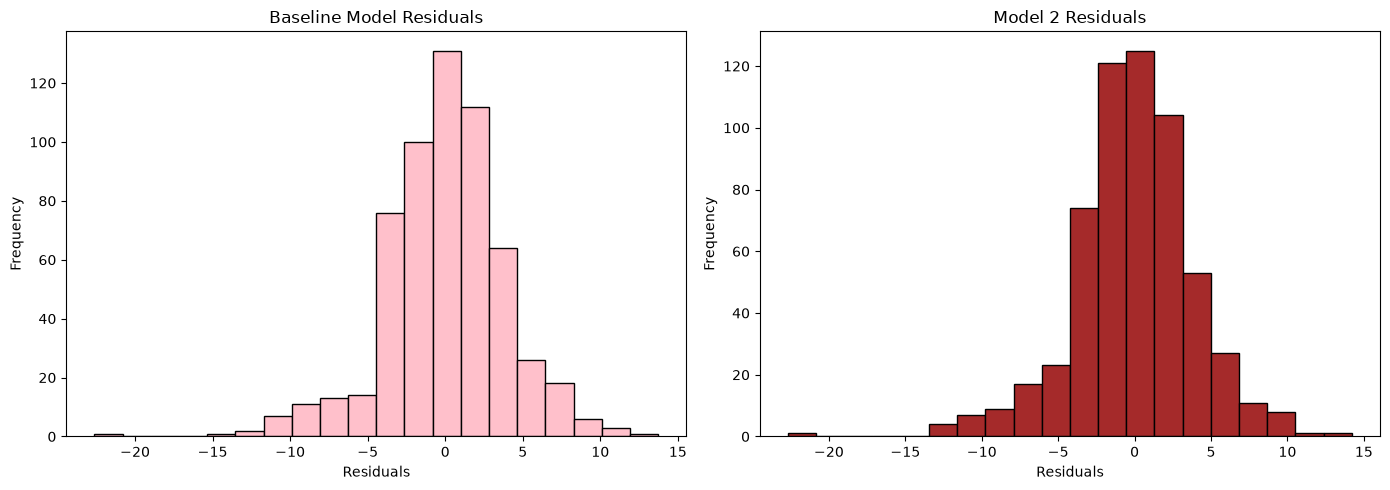

In [118]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Calculate residuals
residuals_baseline = Y_test - Y_predicted
residuals_new = Y2_test - Y2_predicted

# Baseline model
ax1.hist(residuals_baseline, bins=20, color='pink', edgecolor='black')
ax1.set_title('Baseline Model Residuals')
ax1.set_xlabel('Residuals')
ax1.set_ylabel('Frequency')

# Clean model
ax2.hist(residuals_new, bins=20, color='brown', edgecolor='black')
ax2.set_title('Model 2 Residuals')
ax2.set_xlabel('Residuals')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Both models' error distributions have a bell curve shape; however, slightly left skewed.**

## Task 5: The Interaction Investigation

**I chose `Adult Mortality` and `HIV/AIDS` variables because they may have a combined effect on life expectancy because `HIV/AIDS` can contribute to mortality rates, while overall `Adult Mortality` reflects the risk of death among adults.**

In [128]:
df['Interaction'] = df['Adult Mortality'] * df['HIV/AIDS']

### Third model

In [129]:
X3 = df[["Status",
    "Adult Mortality",
    "Alcohol",
    "percentage expenditure",
    "Hepatitis B",
    "Measles",
    "BMI",
    "under-five deaths",
    "Polio",
    "Total expenditure",
    "Diphtheria",
    "HIV/AIDS",
    "Population",
    "thinness 1-19 years",
    "Income composition of resources",
    "Schooling",
    "Interaction"]]
Y3 = df['Life expectancy']

scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)

X3_train, X3_test, Y3_train, Y3_test = train_test_split(X3_scaled, Y3, test_size=0.2, random_state=10)

In [130]:
model3 = LinearRegression()
model3.fit(X3_train, Y3_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](17,)","[-0.46,-3.53, 0.28,..., 1.2 , 1.9 , 2.78]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,69.24
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,17
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(17)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](17,)","[108.59, 73.11, 67.33,..., 25.6 , 21.03, 15.87]"


In [149]:
Y3_predicted = model3.predict(X3_test)
print(f"R-squared score: {r2_score(Y3_test, Y3_predicted):.2f}")
coef3_df = pd.DataFrame({'Feature': X3.columns,
                         'Coefficient': model3.coef_})
print(coef3_df)
print(f"\n The Interaction coefficient is: {model3.coef_[16]:.2f}")

R-squared score: 0.82
                            Feature  Coefficient
0                            Status    -0.458489
1                   Adult Mortality    -3.529591
2                           Alcohol     0.283075
3            percentage expenditure     0.462804
4                       Hepatitis B    -0.410318
5                           Measles    -0.228125
6                               BMI     0.796134
7                 under-five deaths    -0.449617
8                             Polio     0.640853
9                 Total expenditure     0.168294
10                       Diphtheria     1.056605
11                         HIV/AIDS    -4.507647
12                       Population     0.224765
13              thinness 1-19 years    -0.236931
14  Income composition of resources     1.196507
15                        Schooling     1.903936
16                      Interaction     2.779451

 The Interaction coefficient is: 2.78


**The interaction coefficient is positive and has increased the model R-squared score by only 0.01%. Nothing really changed.**